# Viande et masculinité
## Existe-t-il une corrélation entre les normes de genre et la consommation de viande rouge en Europe ?

**Projet de data science — ENSAE Paris, 2A**

Autrices: Solène Pinguet - Noriane Ménard - Emna Larbi · *Date : 24/11/2026*

---

### Résumé
> *À rédiger en dernier (4-5 lignes) : question, données, méthode, résultat principal, limite principale.*

### Plan
0. [Configuration](#1.-Configuration)
1. [Les données](#2.-Les-données)
2. [Contrôles de qualité](#3.-Contrôles-de-qualité)
3. [Statistiques descriptives](#4.-Statistiques-descriptives)
4. [Cartographie](#5.-Cartographie)
5. [Analyse bivariée](#6.-Analyse-bivariée)
6. [Régressions](#7.-Régressions)
7. [Scraping de publicités](#8.-Scraping-de-publicités)
8. [Discussion et conclusion](#9.-Discussion-et-conclusion)
9. [Annexe : reproductibilité](#10.-Annexe-:-reproductibilité)

## 1. Configuration

Le notebook **affiche et commente** ; les calculs sont faits par les scripts de `Src/`, importés ci-dessous.
Avec `RECALCULER = False`, le notebook lit les fichiers déjà produits dans `Data/processed/` (exécution rapide).
Avec `RECALCULER = True`, il relance la chaîne complète depuis `Data/raw/`.

In [8]:
import subprocess
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import Image, Markdown, display

RACINE = Path.cwd()
if not (RACINE / "Src").exists():
    RACINE = next(p for p in [RACINE, *RACINE.parents] if (p / "Src").exists())
SRC = RACINE / "Src"
RAW = RACINE / "Data" / "raw"
PROCESSED = RACINE / "Data" / "processed"
sys.path.insert(0, str(SRC))

RECALCULER = False          # True : relance le nettoyage, la jointure et les cartes
GRAINE = 2020
np.random.seed(GRAINE)

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.family": "serif"})
warnings.filterwarnings("ignore", category=FutureWarning)

print("Racine du projet :", RACINE)

Racine du projet : /home/onyxia/Projet_01_ENSAE_2A


In [9]:
# Chaîne de traitement complète (uniquement si RECALCULER = True).
# Adapter la liste au nom réel des scripts de Src/.
ETAPES = ["clean.py", "maps.py", "carte_masculinite.py"]

if RECALCULER:
    for script in ETAPES:
        print(f"▶ {script}")
        subprocess.run([sys.executable, str(SRC / script)], cwd=RACINE, check=True)
else:
    print("Lecture des fichiers déjà produits dans Data/processed/")

Lecture des fichiers déjà produits dans Data/processed/


In [10]:
import re
from IPython.display import Image, display

# Dossier des sorties de Src/regression.py (cherché automatiquement dans le projet)
SORTIES = RACINE / "sorties"
if not SORTIES.exists():
    SORTIES = next(p for p in RACINE.rglob("sorties") if p.is_dir())
print("Sorties :", SORTIES)


def lire_tableau_tex(chemin) -> pd.DataFrame:
    """Lit le tableau `tabular` d'un fichier .tex et le renvoie en DataFrame
    (Jupyter et GitHub n'affichent pas le LaTeX des tableaux)."""
    tex = Path(chemin).read_text(encoding="utf-8")
    m = re.search(r"\\begin\{tabular\}\{.*?\}(.*?)\\end\{tabular\}", tex, flags=re.S)
    if m is None:
        raise ValueError(f"Aucun tableau dans {chemin}")
    corps = re.sub(r"\\(?:toprule|midrule|bottomrule|hline|cline\{[^}]*\})", "", m.group(1))
    corps = re.sub(r"\\(?:textbf|textit|emph|text)\{([^}]*)\}", r"\1", corps)
    corps = re.sub(r"\\multicolumn\{\d+\}\{[^}]*\}\{([^}]*)\}", r"\1", corps)
    corps = re.sub(r"\$\^\{([^}]*)\}\$", r"\1", corps)
    corps = corps.replace(r"\_", "_").replace(r"\%", "%").replace("$", "").replace("{}", "")
    lignes = [l.strip() for l in re.split(r"\\\\", corps) if l.strip()]
    cellules = [[c.strip() for c in l.split("&")] for l in lignes]
    n = max(len(r) for r in cellules)
    cellules = [r + [""] * (n - len(r)) for r in cellules]
    df = pd.DataFrame(cellules[1:], columns=cellules[0])
    return df.set_index(df.columns[0]).rename_axis(None)


def afficher_sortie(nom: str, largeur: int = 800) -> None:
    """Affiche une sortie de Src/regression.py : tableau .tex ou image .png."""
    chemin = SORTIES / nom
    if not chemin.exists():
        print(f"Sortie absente : {chemin.name} — lancer python Src/regression.py")
    elif chemin.suffix == ".tex":
        display(lire_tableau_tex(chemin))
    else:
        display(Image(chemin, width=largeur))

Sorties : /home/onyxia/Projet_01_ENSAE_2A/sorties


## 2. Les données

### 2.1 Sources

| Source | Années | Contenu utilisé | Unité | Pondération |
|---|---|---|---|---|
| ISSP 2020 — *Environment IV* | 2020-2022 | fréquence de consommation de viande rouge | individu | `poids` |
| ESS round 11 | 2023-2024 | masculinité ressentie (`mascfel`), attitudes | individu | 0-6|
| PIB par habitant | *année à préciser* | niveau de richesse | pays |-|


### 2.2 Variables

| Variable | Source | Question / définition | Échelle |
|---|---|---|---|
| `jours_viande_rouge` | ISSP | fréquence déclarée de consommation de viande rouge | *à préciser* |
| `ecart_h_f` | ISSP (calculée) | moyenne pondérée hommes − moyenne pondérée femmes | - |
| `mascfel` | ESS | « À quel point vous sentez-vous masculin ? » | 0-6 |
| `mascfel_homme`, `mascfel_femme` | ESS (calculées) | moyenne par pays et par sexe | 0-6 |
| `ecart_masc_h_f` | calculée | `mascfel_homme − mascfel_femme` | - |
| `pib_hab` | PIB | PIB par habitant, utilisé en logarithme |-|

### 2.3 Nettoyage


Le nettoyage est réalisé par `Src/clean.py`, qui traite séparément les deux enquêtes puis les agrège au niveau des pays.
Les fichiers produits sont enregistrés dans `Data/processed/`.

#### ISSP 2020 : consommation de viande rouge

**Variables retenues.** Seules cinq variables sont chargées depuis `ISSP_2020.dta` :

| Variable brute | Renommée en | Contenu |
|---|---|---|
| `c_alphan` | `country_iso2` | code pays ISO à deux lettres |
| `country` | `country_code` | code pays numérique ISSP |
| `SEX` | `sexe` | sexe du répondant |
| `v50` | `jours_viande_rouge` | nombre de jours de consommation de viande rouge (fréquence déclarée, pas une quantité) |
| `WEIGHT` | `poids` | poids statistique individuel |

**Codes de non-réponse.** Dans l'ISSP, les codes négatifs ne sont pas des réponses :
- les répondants qui déclarent **ne pas manger de viande** (code −4) sont recodés à **0 jour**. Ils ne consomment
  réellement aucune viande rouge, et les exclure aurait surestimé la consommation moyenne. Ce choix compte d'autant plus que
  les femmes sont plus souvent végétariennes : les retirer aurait mécaniquement réduit l'écart entre hommes et femmes ;
- tous les autres codes négatifs (« ne sait pas », refus, non-réponse) sont traités comme **valeurs manquantes** ;
- le sexe est recodé `1 → homme`, `2 → femme` ; toute autre valeur est considérée comme manquante.

Les répondants sans sexe, sans fréquence de consommation ou sans poids sont ensuite retirés,
car ils ne peuvent pas entrer dans le calcul des moyennes par sexe.

**Pondération.** Les échantillons ISSP ne sont pas parfaitement représentatifs de la population
(certaines catégories sont sur- ou sous-représentées). Toutes les moyennes sont donc **pondérées** par `WEIGHT` :

$$\bar{x}_{\text{pays, sexe}} = \frac{\sum_i w_i\, x_i}{\sum_i w_i}$$

**Agrégation par pays et par sexe.** Pour chaque pays, on calcule :
- `conso_homme` et `conso_femme` : moyennes pondérées de la fréquence de consommation ;
- `n_homme` et `n_femme` : effectifs **bruts** (non pondérés), qui servent à repérer les petits échantillons ;
- `ecart_h_f = conso_homme − conso_femme` : positif quand les hommes déclarent une fréquence plus élevée.

#### ESS 11 : masculinité ressentie et attitudes

**Variables retenues.** Le code pays (`cntry`), le sexe (`gndr`), la masculinité ressentie (`mascfel`),
l'importance d'être un homme ou une femme dans l'identité (`impbemw`) et des variables d'attitudes
(climat, politique, médias, alcool).

**Codes de non-réponse.** Chaque variable ESS a ses propres codes de refus, de « ne sait pas » et de non-réponse
(par exemple 7, 8, 9 pour une échelle de 0 à 6 ; 77, 88, 99 pour une échelle de 0 à 10). Ces codes sont remplacés
par des valeurs manquantes, variable par variable. Une variable `climatosceptique` est créée à partir de `ccnthum`
(1 si le répondant déclare ne pas croire au changement climatique, code 55).

**Lignes incomplètes.** Les répondants ayant une valeur manquante sur au moins une variable sont retirés
(suppression des cas incomplets).

**Agrégation par pays et par sexe.** Pour chaque pays, on calcule la moyenne de chaque variable sur l'ensemble des
répondants, puis `mascfel_homme` et `mascfel_femme`, moyennes de la masculinité ressentie chez les hommes et chez les
femmes, avec leurs effectifs (`n_ess_homme`, `n_ess_femme`). L'agrégation par sexe permet de construire
`ecart_masc_h_f = mascfel_homme − mascfel_femme`, qui se compare directement à l'écart de consommation de viande.


### 2.4 Jointure 
La table d'analyse `Data/processed/table_jointe.csv` est construite par `Src/jointure.py`. Elle réunit,
**pour chaque pays**, trois sources :

| Source | Fichier | Clé pays | Contenu apporté |
|---|---|---|---|
| ESS 11 | `ess11_agrege_pays.csv` | ISO2 (`code_pays`) | masculinité ressentie, attitudes |
| ISSP 2020 | `issp_par_pays.csv` | ISO2 (`country_iso2`) | fréquences de viande rouge par sexe, écart H − F |
| Banque mondiale | `gdp_world_countries_percapita.csv` | ISO3 (`Country Code`) | PIB par habitant |

L'unité d'observation est le **pays** : l'ISSP et l'ESS interrogent des personnes différentes, à des dates
différentes. On ne peut donc rapprocher que des moyennes nationales, pas des individus.

#### Étape 1 : harmonisation des clés

Les colonnes pays des deux enquêtes sont renommées en `iso2` pour servir de clé commune.

#### Étape 2 : contrôles avant jointure

- **Unicité** : on vérifie qu'aucun pays n'apparaît deux fois dans l'ESS ou dans l'ISSP. Un doublon dupliquerait
  des lignes lors de la jointure et fausserait toutes les analyses.
- **Couverture** : on affiche les pays présents dans une seule des deux enquêtes, pour savoir lesquels seront perdus.

#### Étape 3 : jointure ESS × ISSP

Jointure **interne** (`how="inner"`) sur `iso2` : seuls les pays présents **dans les deux enquêtes** sont conservés,
car l'analyse demande à la fois la masculinité ressentie (ESS) et la consommation de viande (ISSP).
L'option `validate="one_to_one"` fait échouer le script si un pays correspondait à plusieurs lignes.

Pays perdus à cette étape :
- présents seulement dans l'ESS : [à compléter] ;
- présents seulement dans l'ISSP : [à compléter, par exemple les pays hors d'Europe].

#### Étape 4 : ajout du PIB par habitant

La Banque mondiale identifie les pays par leur code **ISO3**. On convertit donc `iso2` en `iso3` avec le paquet
`country_converter`, qui applique la norme ISO 3166, puis on fait une jointure **à gauche** (`how="left"`) :
tous les pays de l'étape 3 sont conservés, et un pays absent de la table du PIB aurait une valeur manquante plutôt
que d'être supprimé sans avertissement.

**Année retenue : 2022.** Elle se situe entre les terrains de l'ISSP (2020-2022) et de l'ESS 11 (2023-2024).
Le PIB par habitant évoluant lentement, le choix d'une année voisine changerait peu le classement des pays.

#### Résultat

| | |
|---|---|
| Pays retenus | 15 |
| Colonnes | 24 |
| Valeurs manquantes | aucune dans les variables d'analyse |



## 3. Statistiques descriptives

In [ ]:
afficher_sortie("statistiques_descriptives.tex")


,N,Moyenne,Écart-type,Min,Max
ecart_viande_h_f,15,0.461000,0.195000,0.049000,0.694000
ecart_masc_h_f,15,4.221000,0.749000,2.630000,5.119000
log_pib,15,10.615000,0.573000,9.822000,11.636000


Sur les 15 pays, l'écart de consommation de viande rouge entre hommes et femmes est **positif partout** :
les hommes en déclarent toujours une fréquence plus élevée. Il varie toutefois beaucoup d'un pays à l'autre
(de 0,05 à 0,69, moyenne 0,46). L'écart de masculinité ressentie est élevé dans tous les pays (de 2,6 à 5,1 points,
moyenne 4,2) : les identités de genre sont partout très différenciées, à des degrés variables. 

Le PIB par habitant
varie d'un facteur 6 (d'environ 18 000 $ à 113 000 $), ce qui justifie de le contrôler dans les régressions.
Avec seulement 15 pays, un pays atypique peut peser fortement sur les résultats.

## 4. Cartographie

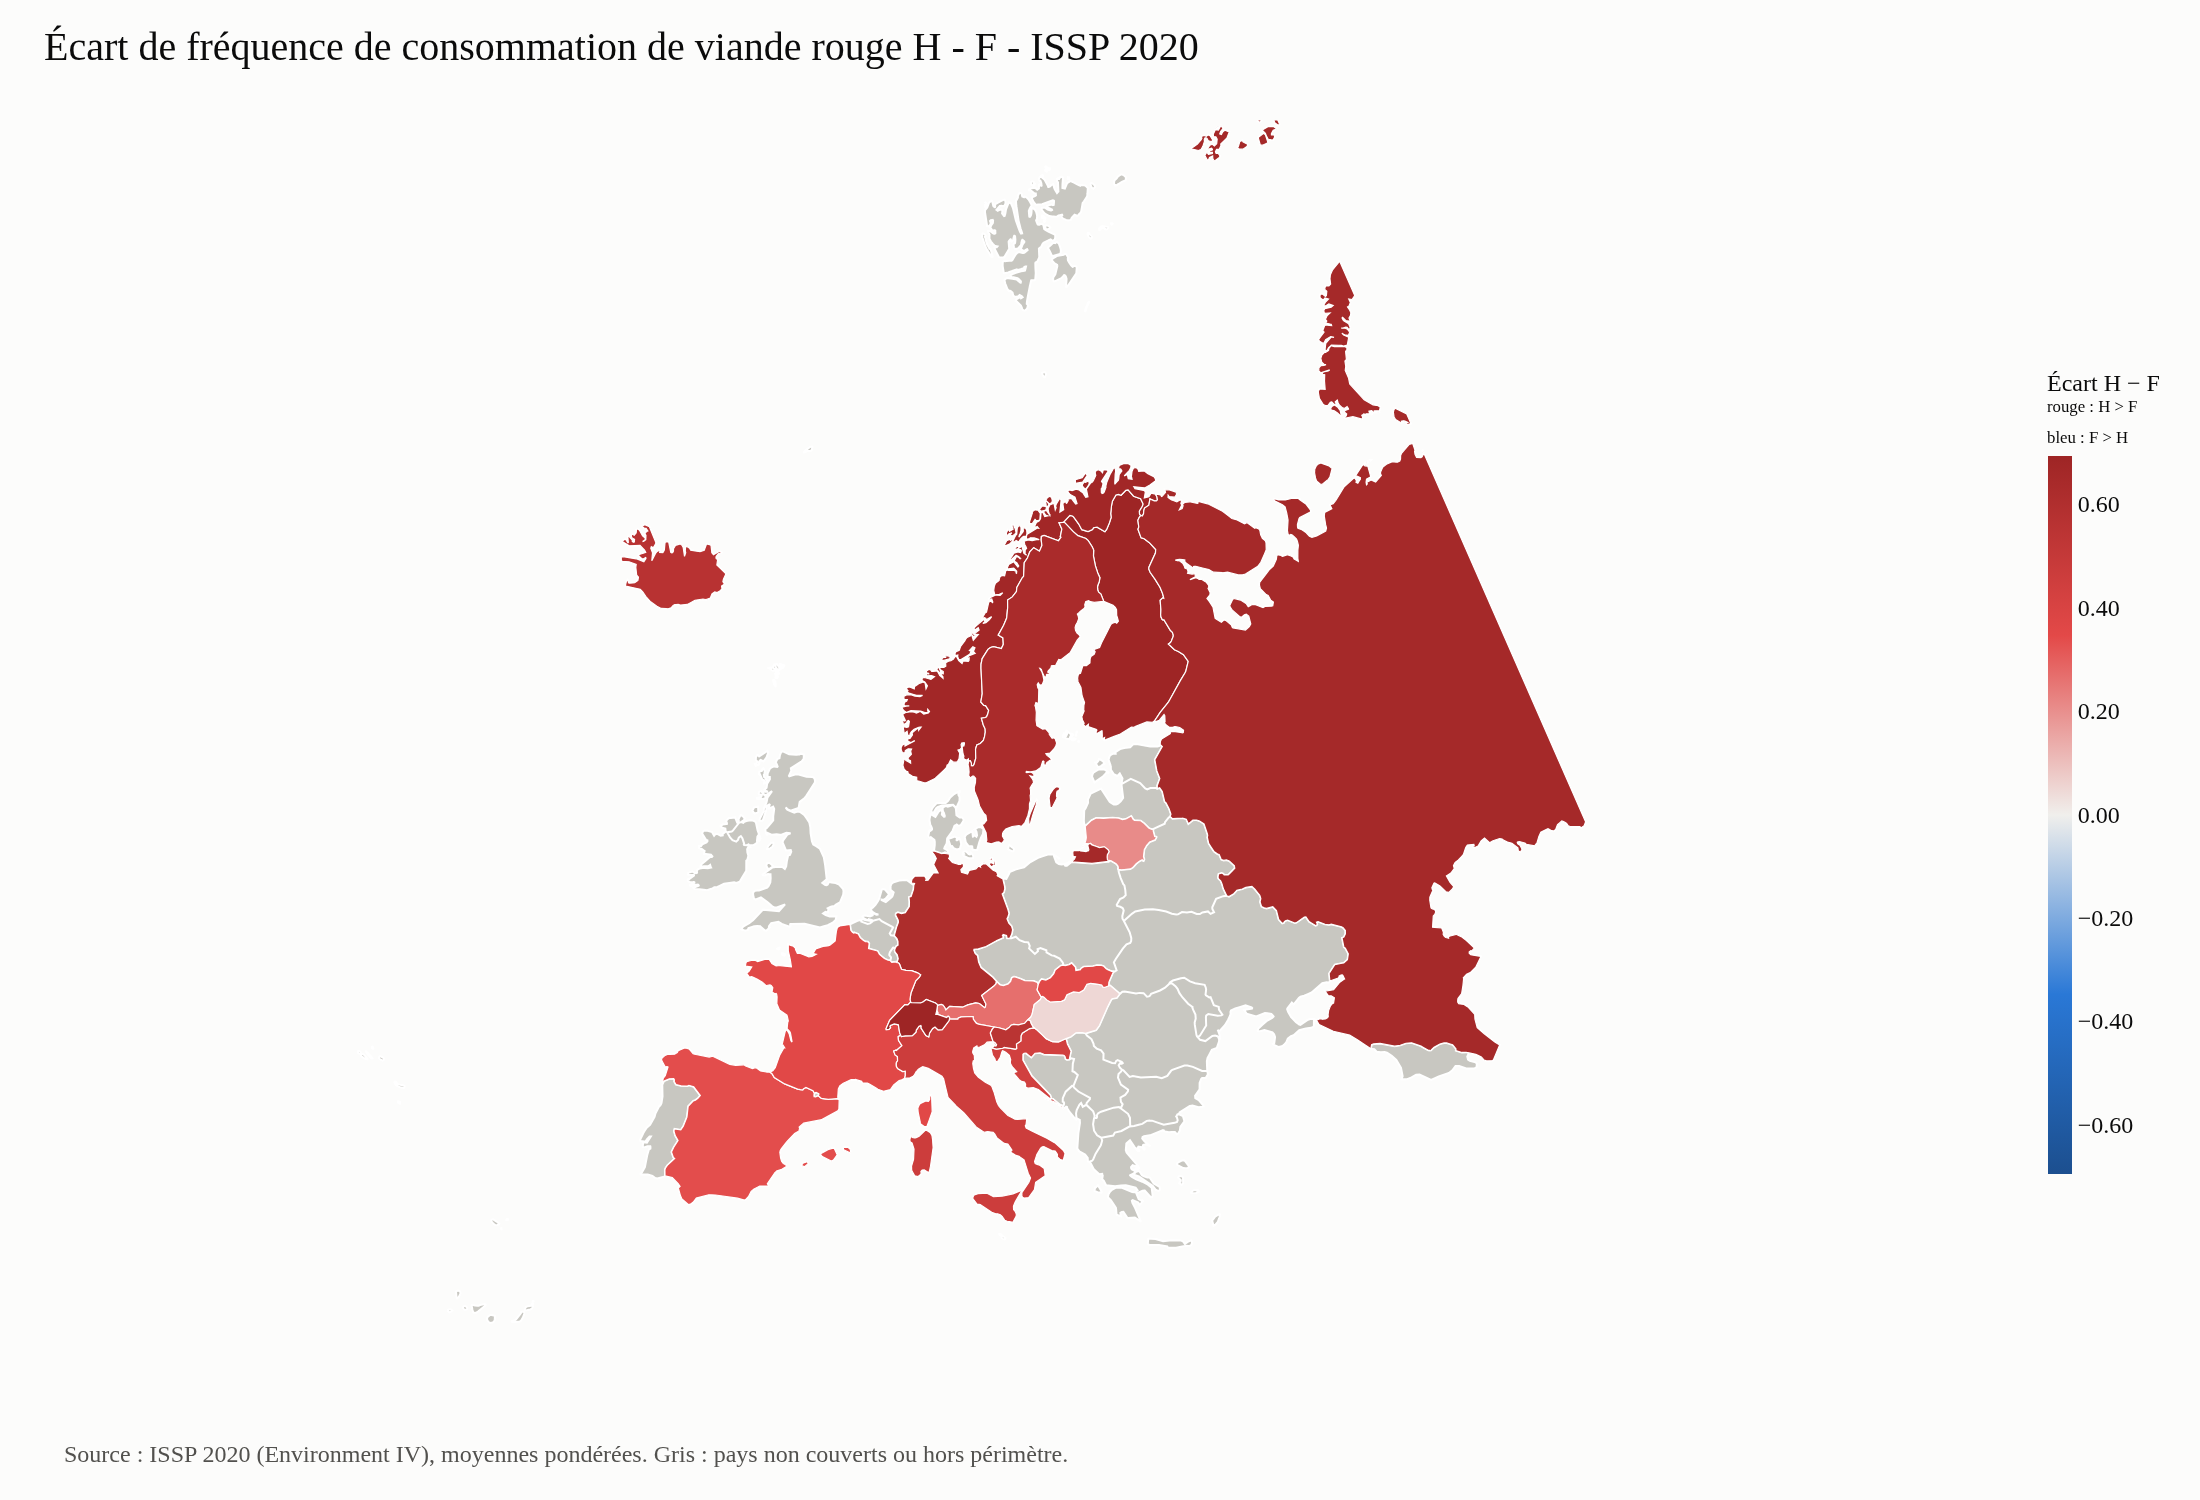

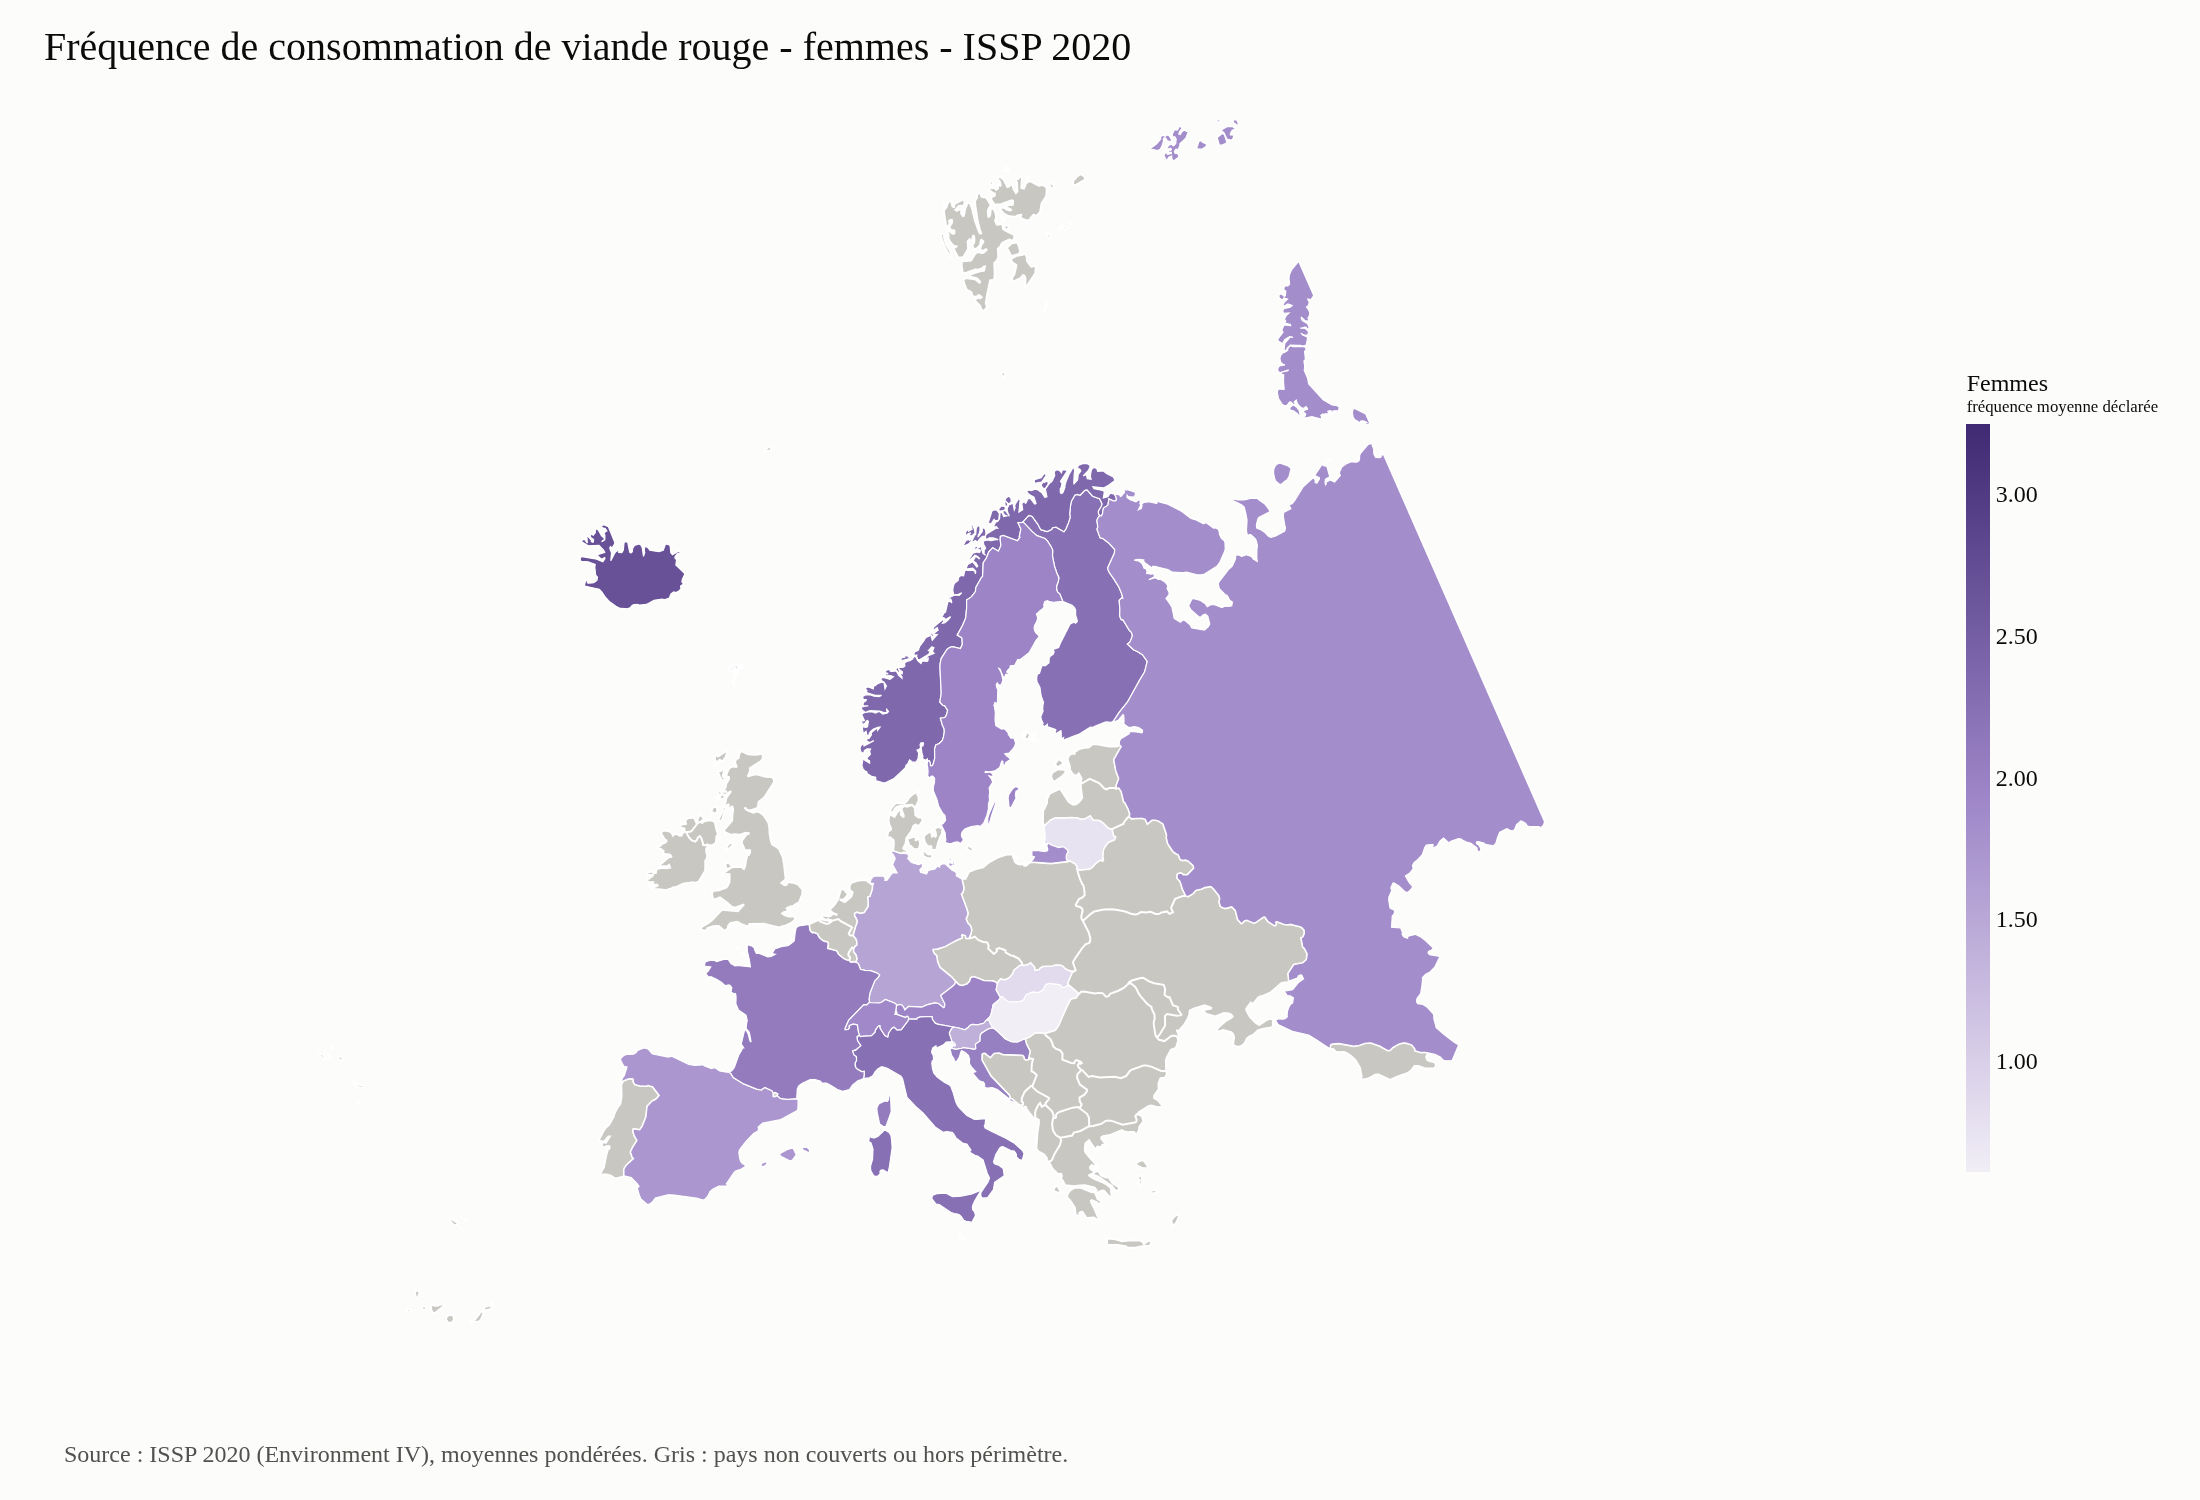

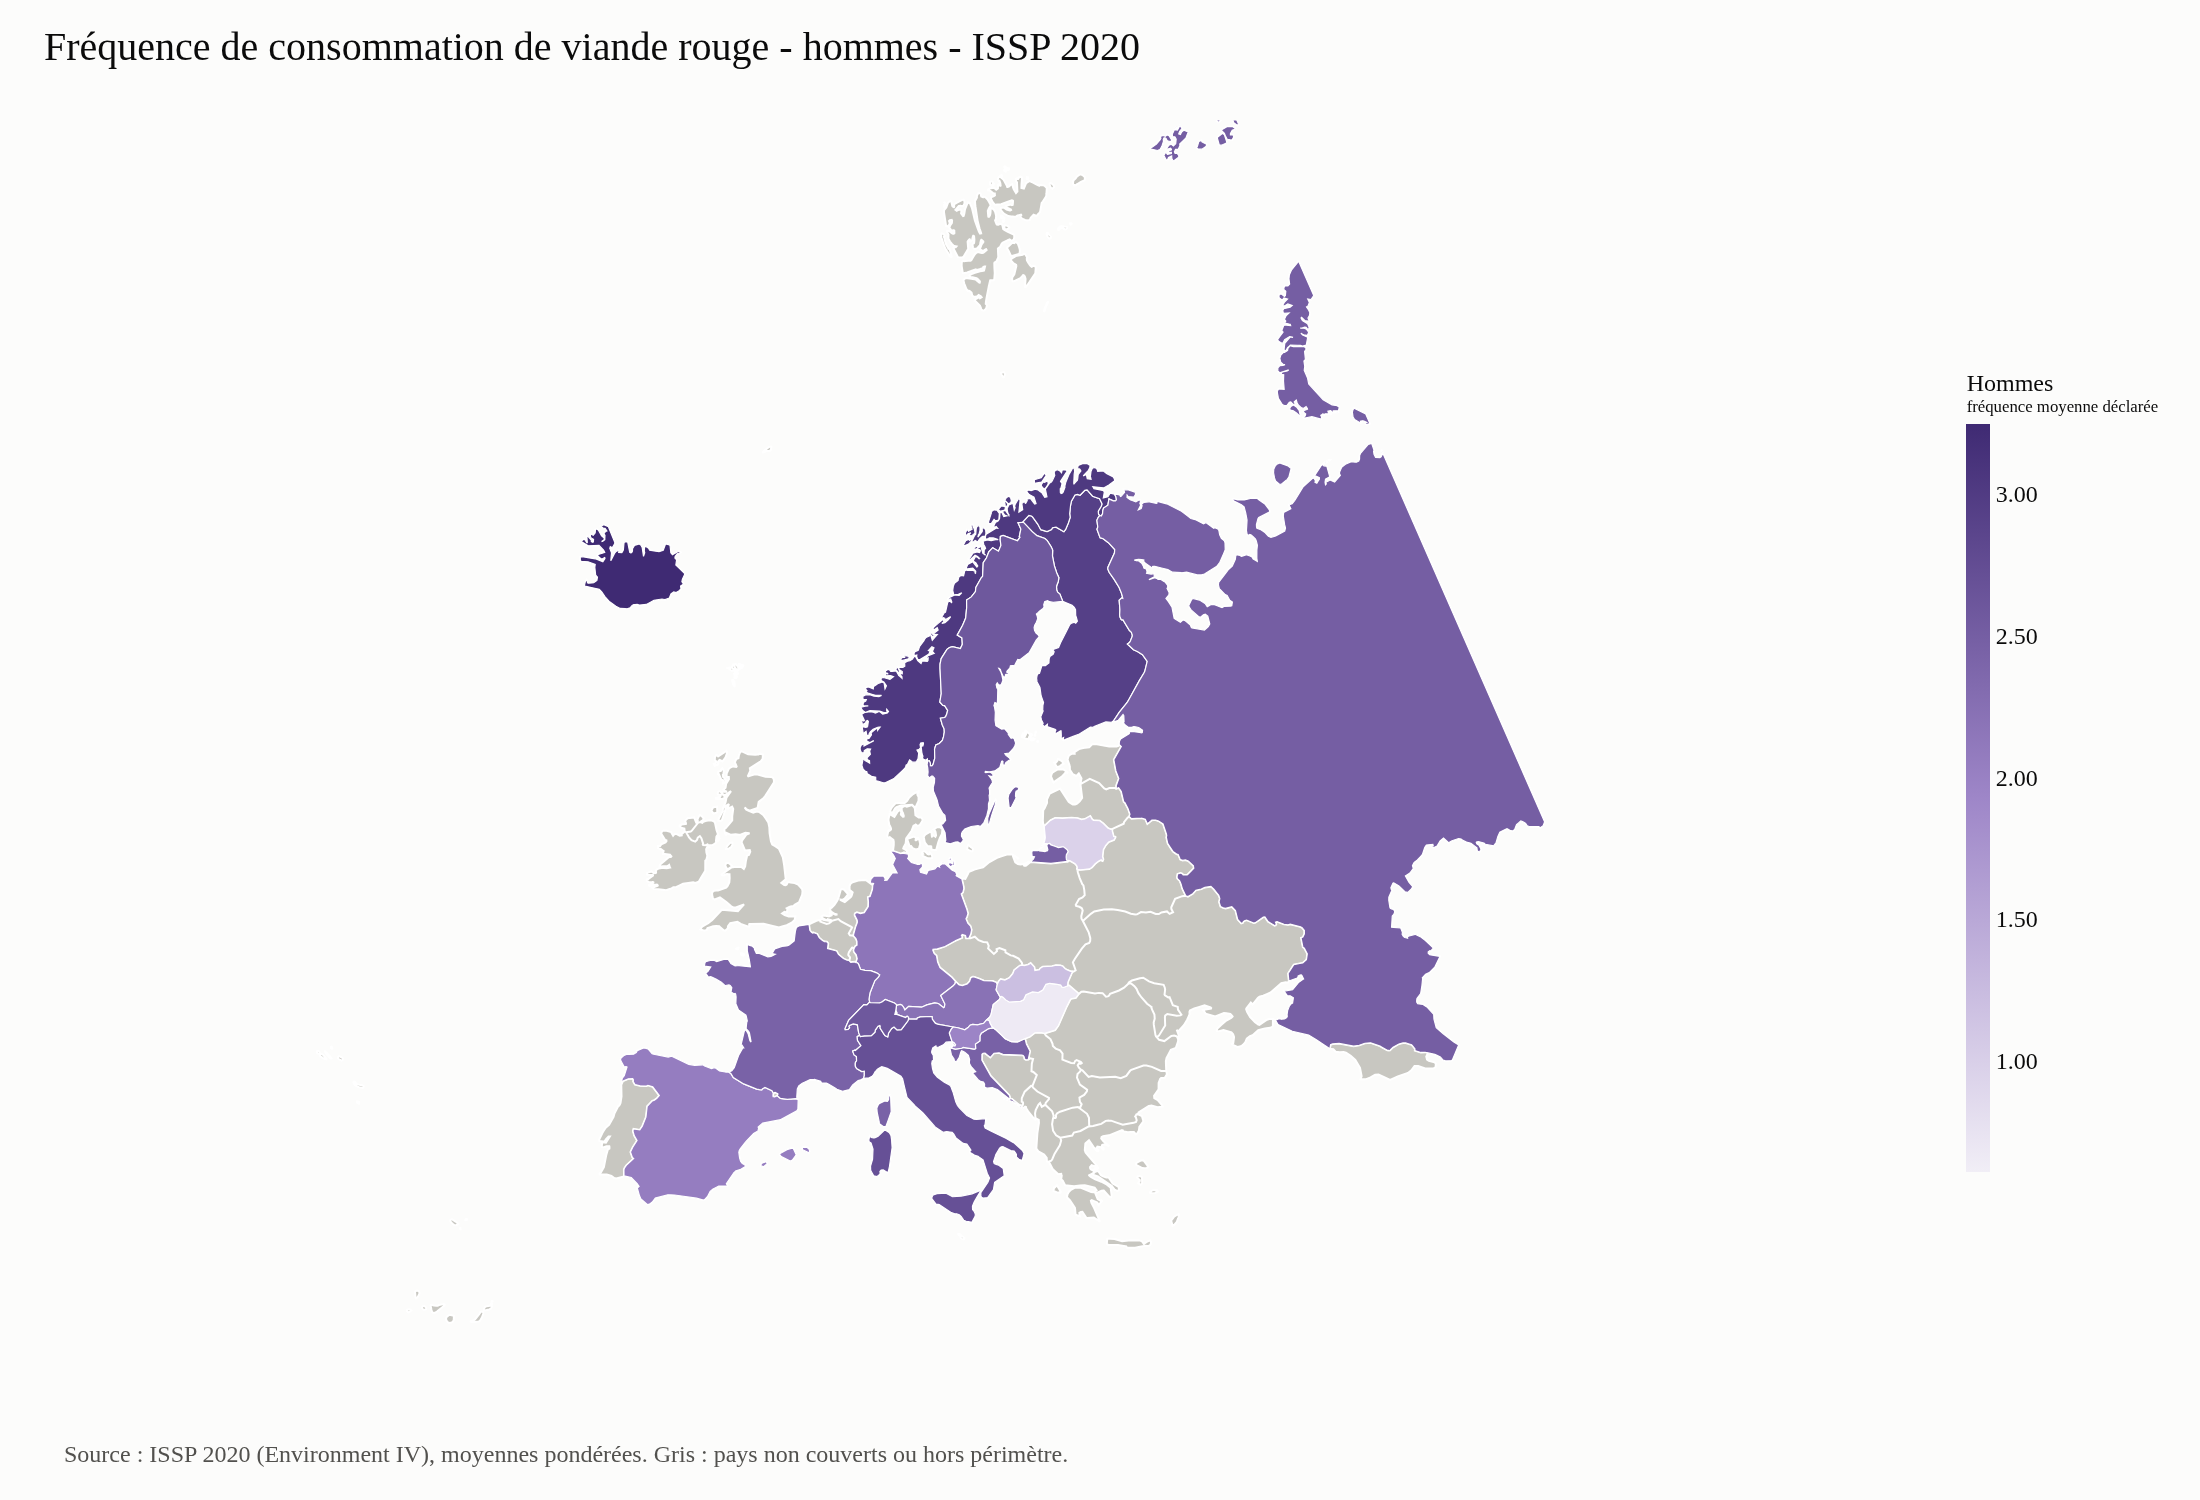

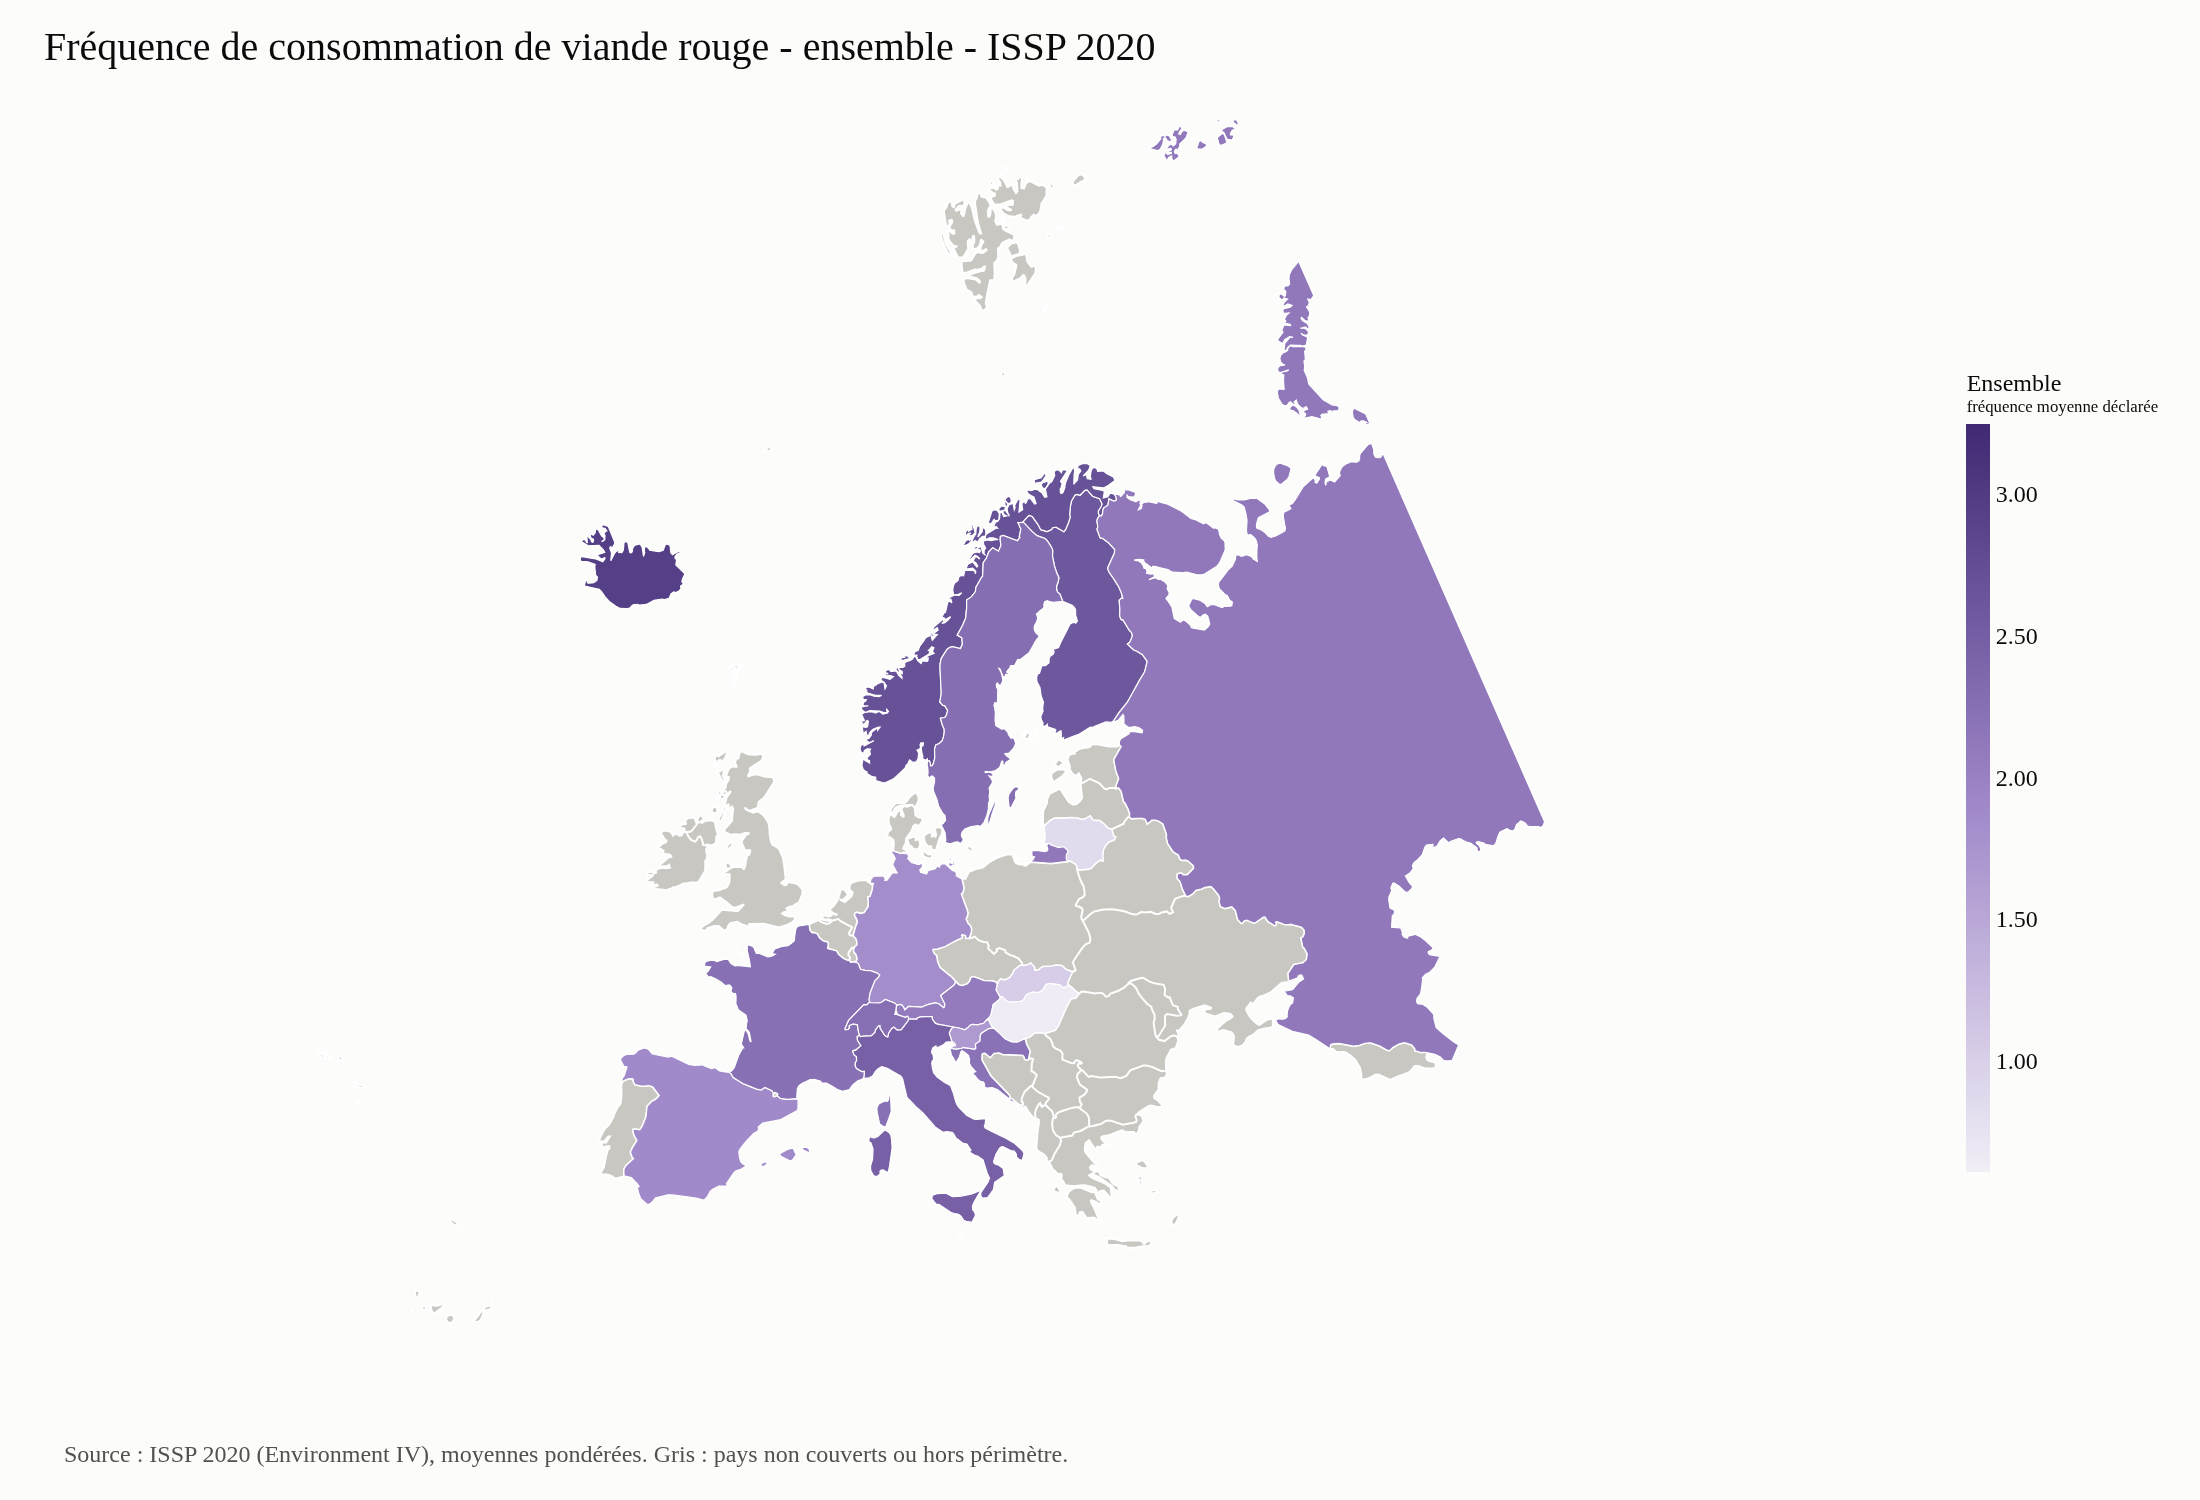

In [12]:
afficher_sortie("carte_viande_ecart.png")
afficher_sortie("carte_viande_femmes.png")
afficher_sortie("carte_viande_hommes.png")
afficher_sortie("carte_viande_tous.png")

**Niveau de consommation** : On observe un contraste important entre pays du Nord et de l'Est. L'Islande, la Norvège et la Finlande sont les plus fortes consommatrices, avec la Suisse, l'Italie et la France. La Hongrie, la Lituanie et la Slovaquie sont nettement en dessous. Les pays nordiques tirent donc bien la moyenne vers le haut, sauf la Suède, qui est dans la moyenne.

**Prise en compte du genre** : Les cartes « hommes » et « femmes » classent les pays presque dans le même ordre, les hommes étant simplement un cran plus haut partout. Il semble donc que la culture alimentaire nationale pèse plus que le sexe dans les différences entre pays.

**Écart hommes − femmes** : Comme établi par les statistiques descriptives, il est positif partout. Toutefois, on voit ici qu'il est plus fort en Suisse, dans les pays nordiques, en Russie, en Allemagne et en Italie, et plus faible en Hongrie (quasi nul) et en Lituanie.

## 6. Régressions

Les estimations sont produites par `Src/regression.py`, qui enregistre ses tableaux et ses figures dans `sorties/`.
Le notebook se contente de les afficher et de les commenter.

### 6.1 Spécification

Au niveau des pays $c$ :

$$\text{écart viande}_c = \alpha + \beta\,\text{écart masculinité}_c + \gamma \log(\text{PIB/hab}_c) + \varepsilon_c$$

- **Écart viande** (`ecart_viande_h_f`) : différence entre hommes et femmes du nombre moyen de jours par semaine
  où l'on mange du bœuf ou de l'agneau (ISSP 2020, moyennes pondérées par `WEIGHT`).
- **Écart masculinité** (`ecart_masc_h_f`) : `mascfel_homme_w − mascfel_femme_w`, différence entre hommes et femmes
  de la masculinité ressentie (échelle de 0 à 6), moyennes pondérées par `anweight` (ESS 11).
- $\beta$ : association entre écart de masculinité et écart de viande **à PIB par habitant égal**.
- PIB en **logarithme** : distribution asymétrique et effet décroissant de la richesse.
- Deux modèles sont estimés par MCO : (1) sans contrôle, (2) avec le log du PIB par habitant.
- Erreurs-types robustes à l'hétéroscédasticité de type **HC3**, recommandées pour les petits échantillons ;
  les tests reposent sur la loi normale.

### 6.2 Résultats

In [ ]:
# Corrélations entre les trois variables du modèle, puis nuage de points par pays
afficher_sortie("correlations.tex")
afficher_sortie("nuage_ecarts.png")

In [ ]:
# Tableau des régressions : erreurs-types HC3 entre parenthèses ; * p<0,1 ; ** p<0,05 ; *** p<0,01
afficher_sortie("tableau_regressions.tex")

**Lecture des résultats.** Le nuage de points montre une relation **négative** : les pays où hommes et femmes
se sentent le plus différents en masculinité sont ceux où l'écart de consommation de viande rouge est le plus faible.
Les pays nordiques (Finlande, Norvège, Suède, Islande) combinent un écart de masculinité modéré et un fort écart
de consommation, tandis que la Hongrie, la Lituanie ou l'Autriche présentent l'inverse.

Dans le modèle (1), sans contrôle, $\hat\beta = -0{,}177$ (erreur-type 0,043), significatif au seuil de 1 % :
un point d'écart de masculinité supplémentaire est associé à un écart de consommation inférieur de 0,18 jour par
semaine. L'écart de masculinité explique à lui seul 46 % de la variance entre pays ($R^2 = 0{,}458$).

Dans le modèle (2), qui contrôle le log du PIB par habitant, le coefficient tombe à $\hat\beta = -0{,}094$
(erreur-type 0,062) et n'est plus significatif, même au seuil de 10 % ($p = 0{,}13$). Le PIB n'est pas
significatif non plus ($\hat\gamma = 0{,}157$, $p = 0{,}12$), alors que le modèle explique 57 % de la variance.
À titre d'ordre de grandeur, un écart-type d'écart de masculinité (0,75 point) correspond à 0,07 jour par semaine
dans le modèle (2), soit environ un tiers d'écart-type de l'écart de consommation.

### 6.3 Lecture du contrôle par le PIB

Le contrôle par le PIB réduit le coefficient de près de moitié (de −0,177 à −0,094). Cette baisse s'explique par
la matrice de corrélation : l'écart de masculinité est fortement corrélé au log du PIB (−0,69), lequel est
lui-même corrélé à l'écart de consommation (0,71). Les pays les plus riches de l'échantillon, en particulier les pays
nordiques et la Suisse, ont à la fois des identités de genre moins polarisées et des écarts de consommation plus marqués.

Une fois les deux variables introduites ensemble, aucune n'est significative isolément, alors que leur pouvoir
explicatif conjoint reste élevé ($R^2 = 0{,}57$). Avec 15 pays et deux régresseurs aussi liés, les données
contiennent trop peu de cas « discordants » (pays riches à fort écart de masculinité, ou l'inverse) pour séparer
leurs effets. Ce résultat ne signifie donc pas que l'association est due à la seule richesse : il indique que
l'échantillon ne permet pas de distinguer la masculinité du niveau de développement.

Plusieurs lectures restent compatibles avec ces chiffres. La richesse peut être un **facteur de confusion**, qui
réduit la polarisation des identités de genre et augmente par ailleurs l'écart de consommation. Elle peut aussi agir
**en amont**, en faisant évoluer les normes de genre qui façonnent à leur tour les pratiques alimentaires, auquel cas
le contrôle masque une partie du rôle de la masculinité. Enfin, l'écart est mesuré en jours : il augmente
mécaniquement avec le niveau de consommation, plus élevé dans les pays riches. Le PIB capterait alors en partie un
**effet de niveau** plutôt qu'un effet propre de la richesse.

### 6.4 Diagnostics

In [ ]:
# Résidus contre valeurs ajustées et distance de Cook par pays, modèle (2)
afficher_sortie("diagnostics.png", largeur=950)

**Lecture des diagnostics.** Les résidus du modèle (2) ne présentent pas de structure visible en fonction des
valeurs ajustées, ce qui ne suggère pas de forme fonctionnelle manifestement mal spécifiée ; avec 15 points,
ce diagnostic reste toutefois peu puissant. Aucun pays ne dépasse le seuil usuel de la distance de Cook
($4/N \approx 0{,}27$). La Hongrie, dont l'écart de consommation est quasi nul, s'en approche nettement plus que
les autres pays et reste l'observation la plus influente. La colinéarité entre les deux régresseurs reste modérée
(VIF de 1,90, très en dessous des seuils habituels de 5 à 10), si bien que la perte de significativité dans le
modèle (2) tient davantage à la petite taille de l'échantillon qu'à une colinéarité sévère.

### 6.5 Interprétation

Entre les 15 pays étudiés, l'écart de masculinité ressentie entre hommes et femmes est **négativement** associé à
l'écart de consommation de viande rouge. Ce signe va à l'encontre de l'intuition selon laquelle des identités de
genre plus polarisées iraient de pair avec des pratiques alimentaires plus différenciées. L'association est nette
sans contrôle, mais elle perd environ la moitié de son ampleur et toute significativité statistique une fois le PIB
par habitant pris en compte. Les données ne permettent donc pas de conclure à un lien propre entre normes de genre
et écart de consommation, indépendamment du niveau de développement.

Ces résultats doivent être lus avec plusieurs réserves :
- **Association et non causalité** : il s'agit d'une corrélation entre moyennes nationales, qui ne dit rien des
  comportements individuels (sophisme écologique) et ne permet pas d'identifier un effet causal.
- **Taille de l'échantillon** : 15 pays seulement, ce qui limite fortement la puissance des tests et rend les
  estimations sensibles à quelques pays, notamment le groupe nordique.
- **Mesure de la consommation** : la question de l'ISSP porte uniquement sur le bœuf et l'agneau, et compte des
  jours de consommation, pas des quantités. Les pays où l'on consomme surtout du porc ou de la volaille sont donc
  imparfaitement décrits, et l'écart exprimé en jours augmente mécaniquement avec le niveau de consommation.
- **Décalage temporel** : la consommation est mesurée vers 2020-2021 (ISSP) et la masculinité en 2023-2024 (ESS 11),
  auprès de répondants différents.

## 7. Scraping de publicités

*Partie à compléter.*

### 7.1 Objectif

*À compléter.*

### 7.2 Source et cadre

*À compléter.*

### 8.3 Collecte

*À compléter.*

### 8.4 Nettoyage

*À compléter.*

### 8.5 Analyse

*À compléter.*

### 8.6 Résultats et limites

*À compléter.*

## 9. Discussion et conclusion

### 9.1 Synthèse des résultats
*…*

### 9.2 Limites
- **Niveau d'analyse** : association entre pays ; aucune conclusion sur les individus (sophisme écologique).
- **Taille d'échantillon** : 15 pays, puissance statistique faible.
- **Mesure** : `mascfel` mesure une identité ressentie, indicateur approché des normes de genre.
- **Données déclaratives** et enquêtes menées à des dates différentes (ISSP 2020, ESS 11).
- **Causalité** : aucune relation causale ne peut être établie.

### 9.3 Pistes
*…*

## 10. Annexe : reproductibilité

Ordre d'exécution depuis la racine du projet :

```bash
pip install -r requirements.txt
python Src/clean.py
python Src/maps.py
python Src/carte_masculinite.py
python Src/regression.py
```

In [ ]:
import importlib.metadata as md_
paquets = ["pandas", "numpy", "statsmodels", "plotly", "pycountry", "matplotlib", "kaleido"]
versions = {}
for p in paquets:
    try:
        versions[p] = md_.version(p)
    except md_.PackageNotFoundError:
        versions[p] = "non installé"
print("Python", sys.version.split()[0])
display(pd.Series(versions, name="version").to_frame())

In [ ]:
print("Fichiers produits dans Data/processed/ :")
for f in sorted(PROCESSED.iterdir()):
    if f.is_file():
        print(f"  {f.name:<45} {f.stat().st_size / 1e6:6.2f} Mo")